In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, precision_recall_curve
)

RANDOM_STATE = 42
OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

# Local setup: put the CSVs under data/raw/. This fallback is for this hosted environment.
DATA_DIR = Path("data/raw")
required_files = [
    "PdM_telemetry.csv", "PdM_errors.csv", "PdM_failures.csv",
    "PdM_machines.csv", "PdM_maint.csv"
]
if not all((DATA_DIR / f).exists() for f in required_files):
    hosted = Path("/mnt/data")
    if all((hosted / f).exists() for f in required_files):
        DATA_DIR = hosted
    else:
        raise FileNotFoundError(
            f"Could not find all five CSV files. Place them under {DATA_DIR.resolve()}"
        )

telemetry = pd.read_csv(DATA_DIR / "PdM_telemetry.csv", parse_dates=["datetime"])
errors = pd.read_csv(DATA_DIR / "PdM_errors.csv", parse_dates=["datetime"])
failures = pd.read_csv(DATA_DIR / "PdM_failures.csv", parse_dates=["datetime"])
machines = pd.read_csv(DATA_DIR / "PdM_machines.csv")
maintenance = pd.read_csv(DATA_DIR / "PdM_maint.csv", parse_dates=["datetime"])

print("Loaded the five dataset files.")
print("Telemetry:", telemetry.shape)
print("Errors:", errors.shape)
print("Failures:", failures.shape)
print("Machines:", machines.shape)
print("Maintenance:", maintenance.shape)
print("Data directory:", DATA_DIR.resolve())

Loaded the five dataset files.
Telemetry: (876100, 6)
Errors: (3919, 3)
Failures: (761, 3)
Machines: (100, 3)
Maintenance: (3286, 3)
Data directory: C:\Users\hazra\Downloads\industrial_pdm_starter\industrial_pdm_starter\data\raw


## 1. Data-quality checks

Check column names, missing values, duplicates, date ranges, and machine-ID consistency before joining or modelling.

In [2]:
frames = {
    "telemetry": telemetry, "errors": errors, "failures": failures,
    "machines": machines, "maintenance": maintenance
}
quality_rows = []
for name, df in frames.items():
    row = {
        "file": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    }
    if "datetime" in df.columns:
        row["start_datetime"] = df["datetime"].min()
        row["end_datetime"] = df["datetime"].max()
        row["unique_machines"] = df["machineID"].nunique()
    quality_rows.append(row)
quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)

known_machine_ids = set(machines["machineID"])
for name, df in frames.items():
    if "machineID" in df.columns:
        unknown = set(df["machineID"]) - known_machine_ids
        print(f"{name}: machine IDs not found in machine metadata = {len(unknown)}")

print("\nTelemetry columns:", telemetry.columns.tolist())
print("Errors columns:", errors.columns.tolist())
print("Failures columns:", failures.columns.tolist())
print("Machines columns:", machines.columns.tolist())
print("Maintenance columns:", maintenance.columns.tolist())

,file,rows,columns,duplicate_rows,missing_cells,start_datetime,end_datetime,unique_machines
0,telemetry,876100,6,0,0,2015-01-01 06:00:00,2016-01-01 06:00:00,100.0
1,errors,3919,3,0,0,2015-01-01 06:00:00,2016-01-01 05:00:00,100.0
2,failures,761,3,0,0,2015-01-02 03:00:00,2015-12-31 06:00:00,98.0
3,machines,100,3,0,0,NaT,NaT,NaN
4,maintenance,3286,3,0,0,2014-06-01 06:00:00,2016-01-01 06:00:00,100.0


telemetry: machine IDs not found in machine metadata = 0
errors: machine IDs not found in machine metadata = 0
failures: machine IDs not found in machine metadata = 0
machines: machine IDs not found in machine metadata = 0
maintenance: machine IDs not found in machine metadata = 0

Telemetry columns: ['datetime', 'machineID', 'volt', 'rotate', 'pressure', 'vibration']
Errors columns: ['datetime', 'machineID', 'errorID']
Failures columns: ['datetime', 'machineID', 'failure']
Machines columns: ['machineID', 'model', 'age']
Maintenance columns: ['datetime', 'machineID', 'comp']


## 2. Descriptive analytics

Summarize sensor ranges and event counts. These statistics describe the supplied benchmark data; they are not engineering safety limits.

In [4]:
sensor_cols = ["volt", "rotate", "pressure", "vibration"]
sensor_summary = telemetry[sensor_cols].describe().T.round(3)
display(sensor_summary)
sensor_summary.to_csv(OUTPUT_DIR / "sensor_summary.csv")

print("Error event counts:")
display(errors["errorID"].value_counts().rename_axis("errorID").reset_index(name="count"))
print("Recorded component failure counts:")
display(failures["failure"].value_counts().rename_axis("component" ).reset_index(name="count"))
print("Maintenance/replacement record counts:")
display(maintenance["comp"].value_counts().rename_axis("component").reset_index(name="count"))
print("Machine models:")
display(machines["model"].value_counts().rename_axis("model").reset_index(name="count"))

,count,mean,std,min,25%,50%,75%,max
volt,876100.0,170.778,15.509,97.334,160.305,170.607,181.004,255.125
rotate,876100.0,446.605,52.674,138.432,412.306,447.558,482.177,695.021
pressure,876100.0,100.859,11.049,51.237,93.498,100.426,107.555,185.952
vibration,876100.0,40.385,5.370,14.877,36.777,40.237,43.785,76.791


Error event counts:


,errorID,count
0,error1,1010
1,error2,988
2,error3,838
3,error4,727
4,error5,356


Recorded component failure counts:


,component,count
0,comp2,259
1,comp1,192
2,comp4,179
3,comp3,131


Maintenance/replacement record counts:


,component,count
0,comp2,863
1,comp4,811
2,comp3,808
3,comp1,804


Machine models:


,model,count
0,model3,35
1,model4,32
2,model2,17
3,model1,16


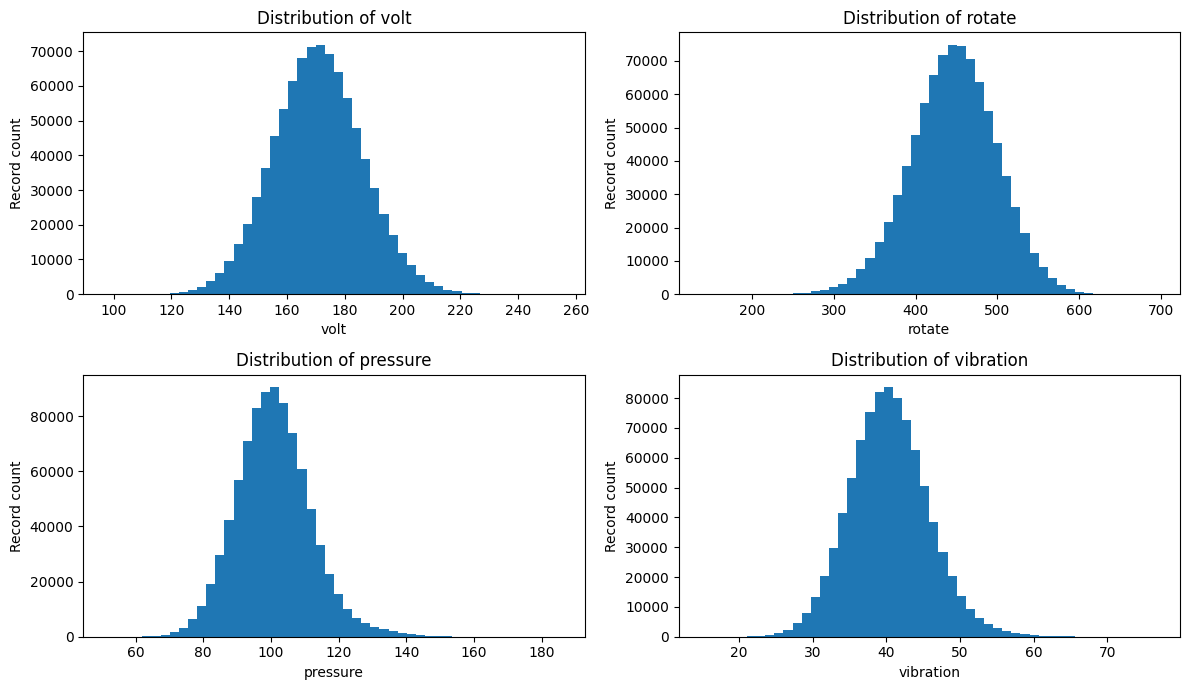

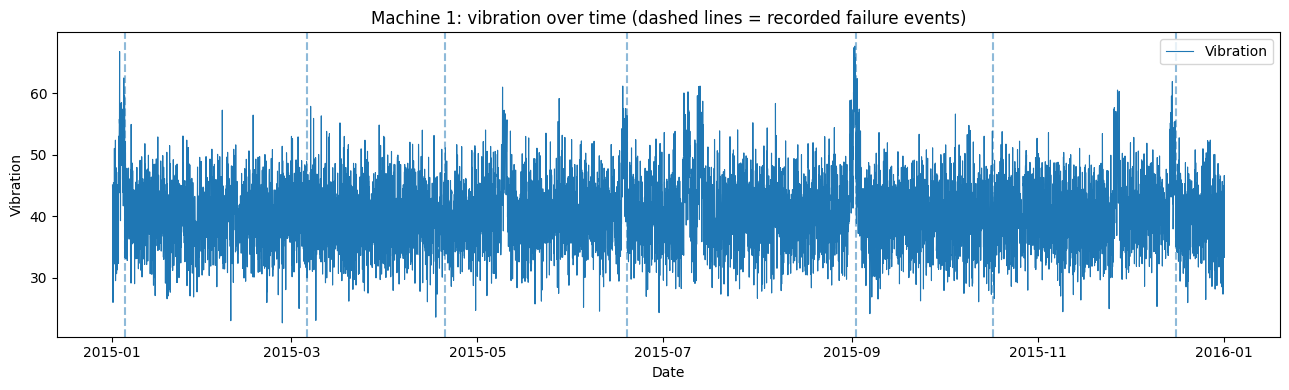

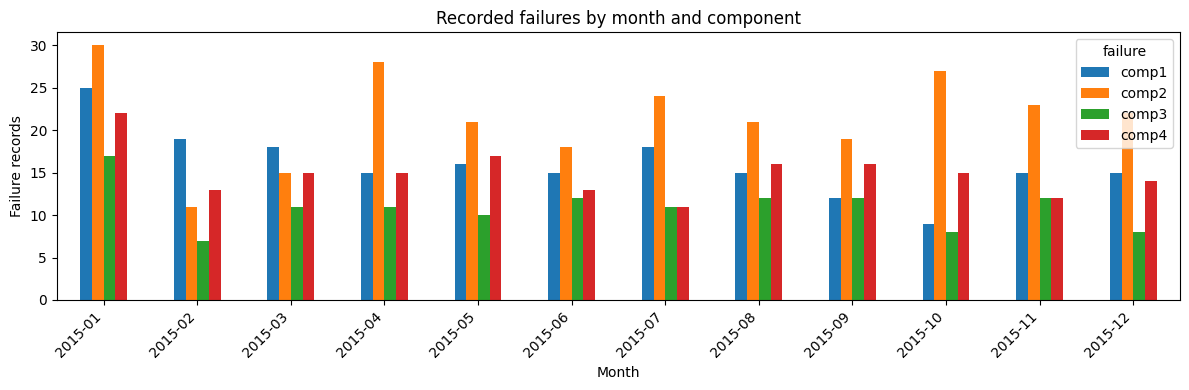

,machineID,first_recorded_maintenance,last_recorded_maintenance,maintenance_records
0,1,2014-06-01 06:00:00,2015-12-31 06:00:00,37
1,2,2014-06-16 06:00:00,2015-12-29 06:00:00,32
2,3,2014-06-16 06:00:00,2015-12-18 06:00:00,37
3,4,2014-06-16 06:00:00,2015-12-28 06:00:00,33
4,5,2014-08-15 06:00:00,2015-12-20 06:00:00,35


In [5]:
# Plot 1: sensor distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.ravel(), sensor_cols):
    ax.hist(telemetry[col], bins=50)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Record count")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sensor_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

# Plot 2: one machine's sensor trends and failure events
machine_to_plot = 1
sample = telemetry.loc[telemetry.machineID == machine_to_plot].sort_values("datetime")
fail_sample = failures.loc[failures.machineID == machine_to_plot]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sample.datetime, sample.vibration, linewidth=0.8, label="Vibration")
for t in fail_sample.datetime:
    ax.axvline(t, linestyle="--", alpha=0.5)
ax.set_title(f"Machine {machine_to_plot}: vibration over time (dashed lines = recorded failure events)")
ax.set_xlabel("Date")
ax.set_ylabel("Vibration")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "machine1_vibration_failures.png", dpi=160, bbox_inches="tight")
plt.show()

# Plot 3: monthly count of failures
failure_monthly = failures.assign(month=failures.datetime.dt.to_period("M").astype(str)).groupby(["month", "failure"]).size().unstack(fill_value=0)
ax = failure_monthly.plot(kind="bar", figsize=(12, 4))
ax.set_title("Recorded failures by month and component")
ax.set_xlabel("Month")
ax.set_ylabel("Failure records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_failures_by_component.png", dpi=160, bbox_inches="tight")
plt.show()

# Save machine-level maintenance summary
maintenance_summary = (maintenance.sort_values("datetime")
    .groupby("machineID")
    .agg(first_recorded_maintenance=("datetime", "min"),
         last_recorded_maintenance=("datetime", "max"),
         maintenance_records=("comp", "size"))
    .reset_index())
maintenance_summary.to_csv(OUTPUT_DIR / "maintenance_summary_by_machine.csv", index=False)
display(maintenance_summary.head())

## 3. Build model features without using future information

Features below combine current sensor readings, rolling sensor summaries, the count of recent error events, time since the last recorded maintenance/replacement event, and machine metadata. Rolling calculations are backward-looking. The model target is created separately from future failure records.

**Caution:** the maintenance file records component maintenance/replacement events; it does not itself provide a universal repair duration or exact machine downtime.

In [6]:
# Sort telemetry chronologically by machine
base = telemetry.sort_values(["machineID", "datetime"]).copy()
base = base.merge(machines, on="machineID", how="left", validate="many_to_one")

# Backward-looking rolling sensor features (current sample is included)
for col in sensor_cols:
    grouped = base.groupby("machineID", sort=False)[col]
    base[f"{col}_mean_6h"] = grouped.transform(lambda s: s.rolling(6, min_periods=1).mean())
    base[f"{col}_std_6h"] = grouped.transform(lambda s: s.rolling(6, min_periods=2).std()).fillna(0)

# Count error events in the previous 24 hours, including events at current timestamp
base["error_count_prev24h"] = 0
for mid, idx in base.groupby("machineID", sort=False).groups.items():
    row_times = base.loc[idx, "datetime"].astype("int64").to_numpy()
    err_times = errors.loc[errors.machineID == mid, "datetime"].sort_values().astype("int64").to_numpy()
    if len(err_times):
        left = np.searchsorted(err_times, row_times - pd.Timedelta(hours=24).value, side="right")
        right = np.searchsorted(err_times, row_times, side="right")
        base.loc[idx, "error_count_prev24h"] = right - left

# Time since most recent known maintenance event at or before each telemetry timestamp
base["hours_since_maintenance"] = np.nan
for mid, idx in base.groupby("machineID", sort=False).groups.items():
    row_times = base.loc[idx, "datetime"].astype("int64").to_numpy()
    maint_times = maintenance.loc[maintenance.machineID == mid, "datetime"].sort_values().astype("int64").to_numpy()
    pos = np.searchsorted(maint_times, row_times, side="right") - 1
    known = pos >= 0
    hours = np.full(len(row_times), np.nan, dtype=float)
    hours[known] = (row_times[known] - maint_times[pos[known]]) / pd.Timedelta(hours=1).value
    base.loc[idx, "hours_since_maintenance"] = hours

base["hour_of_day"] = base.datetime.dt.hour
base["day_of_week"] = base.datetime.dt.dayofweek
base["month"] = base.datetime.dt.month
base = pd.get_dummies(base, columns=["model"], prefix="model", dtype=int)

print("Feature table shape:", base.shape)
print("Missing values among sensor/engineered features:")
engineered_cols = sensor_cols + [f"{c}_mean_6h" for c in sensor_cols] + [f"{c}_std_6h" for c in sensor_cols] + ["error_count_prev24h", "hours_since_maintenance", "age", "hour_of_day", "day_of_week", "month"]
print(base[engineered_cols].isna().sum().sort_values(ascending=False).head(10))

# Create target: any recorded component failure strictly after the row time and within 24 hours.
# Use only rows where the entire 24-hour outcome window is covered by the failure log.
horizon = pd.Timedelta(hours=24)
max_failure_time = failures.datetime.max()
label_cutoff = max_failure_time - horizon
base["failure_next_24h"] = 0
for mid, idx in base.groupby("machineID", sort=False).groups.items():
    row_times = base.loc[idx, "datetime"].astype("int64").to_numpy()
    fail_times = failures.loc[failures.machineID == mid, "datetime"].sort_values().astype("int64").to_numpy()
    if len(fail_times):
        future_pos = np.searchsorted(fail_times, row_times, side="right")
        within = future_pos < len(fail_times)
        pos_safe = np.minimum(future_pos, len(fail_times) - 1)
        within &= fail_times[pos_safe] <= row_times + horizon.value
        base.loc[idx, "failure_next_24h"] = within.astype(int)

# Remove samples whose 24-hour target horizon is not fully covered by the failure log.
model_data = base.loc[base.datetime <= label_cutoff].copy()
print("Failure log ends at:", max_failure_time)
print("Rows usable with full 24-hour label window:", len(model_data))
print("Positive target rows:", int(model_data.failure_next_24h.sum()))
print("Positive target prevalence (%):", round(100 * model_data.failure_next_24h.mean(), 3))

model_data.head(5000).to_csv(OUTPUT_DIR / "feature_table_preview.csv", index=False)
# Only save a 5,000-row preview; the full feature table is intentionally not exported due to its size.

Feature table shape: (876100, 24)
Missing values among sensor/engineered features:
volt                 0
rotate               0
pressure             0
vibration            0
volt_mean_6h         0
rotate_mean_6h       0
pressure_mean_6h     0
vibration_mean_6h    0
volt_std_6h          0
rotate_std_6h        0
dtype: int64
Failure log ends at: 2015-12-31 06:00:00
Rows usable with full 24-hour label window: 871300
Positive target rows: 17092
Positive target prevalence (%): 1.962


## 4. Anomaly-detection baseline: Isolation Forest

Fit on a sample of earlier sensor records and flag unusual sensor combinations. This is an exploratory baseline: an anomaly is not automatically a failure or a root cause.

Test-period sample rows: 142300
Rows flagged anomalous (%): 1.08
Failure-next-24h prevalence in this sample (%): 1.82
Failure-window recall among flagged rows (exploratory only): 0.0614


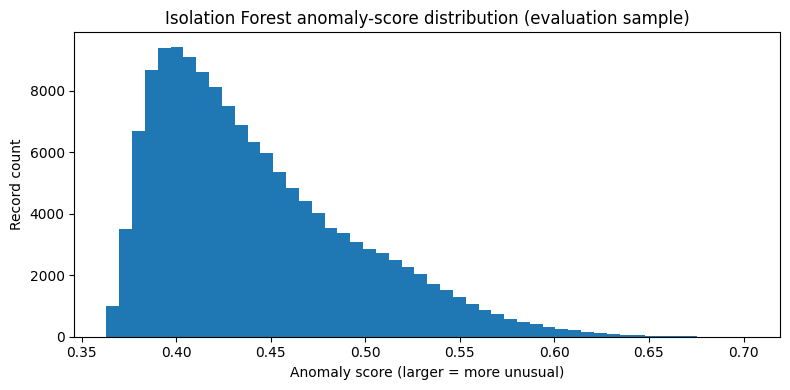

In [7]:
anomaly_features = sensor_cols
train_anom = base.loc[base.datetime < pd.Timestamp("2015-09-01"), anomaly_features].dropna()
train_sample = train_anom.sample(n=min(60000, len(train_anom)), random_state=RANDOM_STATE)
iso = IsolationForest(n_estimators=100, contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(train_sample)

# Score a manageable test-period slice
anom_eval = model_data.loc[model_data.datetime >= pd.Timestamp("2015-11-01")].copy()
if len(anom_eval) > 150000:
    anom_eval = anom_eval.sample(n=150000, random_state=RANDOM_STATE)
anom_eval["anomaly_flag"] = (iso.predict(anom_eval[anomaly_features]) == -1).astype(int)
anom_eval["anomaly_score"] = -iso.score_samples(anom_eval[anomaly_features])
print("Test-period sample rows:", len(anom_eval))
print("Rows flagged anomalous (%):", round(100 * anom_eval.anomaly_flag.mean(), 2))
print("Failure-next-24h prevalence in this sample (%):", round(100 * anom_eval.failure_next_24h.mean(), 3))
print("Failure-window recall among flagged rows (exploratory only):", round(recall_score(anom_eval.failure_next_24h, anom_eval.anomaly_flag, zero_division=0), 4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(anom_eval.anomaly_score, bins=50)
ax.set_title("Isolation Forest anomaly-score distribution (evaluation sample)")
ax.set_xlabel("Anomaly score (larger = more unusual)")
ax.set_ylabel("Record count")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "isolation_forest_score_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
anom_eval[["datetime", "machineID", "anomaly_score", "anomaly_flag", "failure_next_24h"]].to_csv(OUTPUT_DIR / "anomaly_sample_results.csv", index=False)

## 5. Predictive-maintenance baseline

**Task:** predict whether any recorded component failure will occur within the next 24 hours. Use chronological train/validation/test partitions. This baseline is for demonstrating the modelling workflow; the target should be refined with your guide before making operational claims.

Train range/rows: 2015-01-01 06:00:00 to 2015-08-30 23:00:00 580200
Validation range/rows: 2015-09-01 00:00:00 to 2015-10-31 23:00:00 146400
Test range/rows: 2015-11-01 00:00:00 to 2015-12-30 06:00:00 142300
train positive prevalence: 2.0238% (11742 positive rows)
validation positive prevalence: 1.8607% (2724 positive rows)
test positive prevalence: 1.8201% (2590 positive rows)


,value
target,failure recorded within next 24 hours
threshold_selected_on_validation,0.855605
test_rows,142300
test_positive_rows,2590
test_prevalence,0.018201
average_precision_PR_AUC,0.795377
ROC_AUC,0.995762
precision_at_validation_threshold,0.694278
recall_at_validation_threshold,0.805792
F1_at_validation_threshold,0.74589


Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):
[[138791    919]
 [   503   2087]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99    139710
           1       0.69      0.81      0.75      2590

    accuracy                           0.99    142300
   macro avg       0.85      0.90      0.87    142300
weighted avg       0.99      0.99      0.99    142300



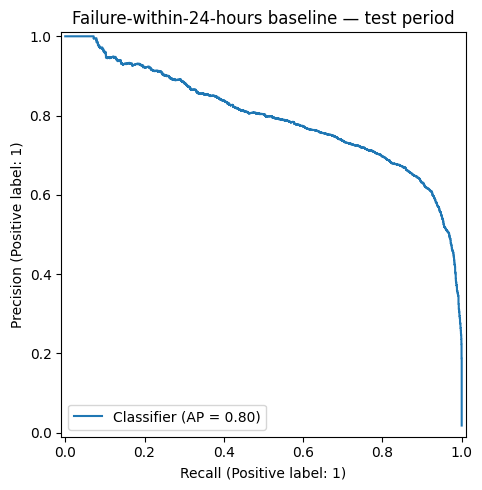


Reminder: the class-weighted model's predicted scores are ranking/risk scores and should not be treated as calibrated failure probabilities without a separate calibration check.


In [7]:
model_feature_cols = (
    sensor_cols
    + [f"{c}_mean_6h" for c in sensor_cols]
    + [f"{c}_std_6h" for c in sensor_cols]
    + ["error_count_prev24h", "hours_since_maintenance", "age", "hour_of_day", "day_of_week", "month"]
    + [c for c in base.columns if c.startswith("model_")]
)

# Ensure finite numeric inputs.
for col in model_feature_cols:
    model_data[col] = pd.to_numeric(model_data[col], errors="coerce")
model_data[model_feature_cols] = model_data[model_feature_cols].replace([np.inf, -np.inf], np.nan)
model_data = model_data.dropna(subset=model_feature_cols + ["failure_next_24h"]).copy()

train_end = pd.Timestamp("2015-09-01")
val_end = pd.Timestamp("2015-11-01")
# Purge the last 24 hours before the train boundary, because training labels look 24 hours forward.
train = model_data.loc[model_data.datetime < train_end - horizon]
val = model_data.loc[(model_data.datetime >= train_end) & (model_data.datetime < val_end)]
test = model_data.loc[(model_data.datetime >= val_end) & (model_data.datetime <= label_cutoff)]

print("Train range/rows:", train.datetime.min(), "to", train.datetime.max(), len(train))
print("Validation range/rows:", val.datetime.min(), "to", val.datetime.max(), len(val))
print("Test range/rows:", test.datetime.min(), "to", test.datetime.max(), len(test))
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name} positive prevalence: {part.failure_next_24h.mean():.4%} ({int(part.failure_next_24h.sum())} positive rows)")

if min(len(train), len(val), len(test)) == 0 or train.failure_next_24h.nunique() < 2:
    raise ValueError("A temporal partition is empty or has only one target class. Inspect date ranges before modelling.")

# Baseline Logistic Regression. Class weighting helps address imbalanced failure labels.
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=200, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE)
)
model.fit(train[model_feature_cols], train.failure_next_24h)
val_prob = model.predict_proba(val[model_feature_cols])[:, 1]
test_prob = model.predict_proba(test[model_feature_cols])[:, 1]

# Select a threshold on validation only, then evaluate that fixed threshold on test.
prec, rec, thresholds = precision_recall_curve(val.failure_next_24h, val_prob)
if len(thresholds):
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    threshold = float(thresholds[int(np.nanargmax(f1s))])
else:
    threshold = 0.5

test_pred = (test_prob >= threshold).astype(int)
metrics = {
    "target": "failure recorded within next 24 hours",
    "threshold_selected_on_validation": threshold,
    "test_rows": int(len(test)),
    "test_positive_rows": int(test.failure_next_24h.sum()),
    "test_prevalence": float(test.failure_next_24h.mean()),
    "average_precision_PR_AUC": float(average_precision_score(test.failure_next_24h, test_prob)),
    "ROC_AUC": float(roc_auc_score(test.failure_next_24h, test_prob)) if test.failure_next_24h.nunique() == 2 else float("nan"),
    "precision_at_validation_threshold": float(precision_score(test.failure_next_24h, test_pred, zero_division=0)),
    "recall_at_validation_threshold": float(recall_score(test.failure_next_24h, test_pred, zero_division=0)),
    "F1_at_validation_threshold": float(f1_score(test.failure_next_24h, test_pred, zero_division=0)),
}
metrics_df = pd.DataFrame([metrics])
display(metrics_df.T.rename(columns={0: "value"}))
metrics_df.to_csv(OUTPUT_DIR / "predictive_model_metrics.csv", index=False)
print("Confusion matrix (rows=actual [0,1], columns=predicted [0,1]):")
print(confusion_matrix(test.failure_next_24h, test_pred))
print("\nClassification report:")
print(classification_report(test.failure_next_24h, test_pred, zero_division=0))

# Plot precision-recall curve on the held-out test period
from sklearn.metrics import PrecisionRecallDisplay
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(test.failure_next_24h, test_prob, ax=ax)
ax.set_title("Failure-within-24-hours baseline — test period")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "predictive_model_precision_recall.png", dpi=160, bbox_inches="tight")
plt.show()

predictions = test[["datetime", "machineID", "failure_next_24h"]].copy()
predictions["predicted_risk_score"] = test_prob
predictions["predicted_failure_next_24h"] = test_pred
predictions.to_csv(OUTPUT_DIR / "test_period_predictions.csv", index=False)

print("\nReminder: the class-weighted model's predicted scores are ranking/risk scores and should not be treated as calibrated failure probabilities without a separate calibration check.")

## 6. What-if scenario — implement only after the baseline is checked

For this dataset, you can test modified sensor parameters (e.g. pressure or rotation). It does **not** contain a universal load/capacity percentage, so do not label these scenarios as 90% to 95% load. A change to an input feature is only a model scenario; it is not proof that the real machine's failure time will causally change.

The first implementation milestone is complete when the data checks, descriptive plots, anomaly baseline and chronologically evaluated prediction baseline all run and you can explain their limitations.